# MNIST: DDPM vs Rectified Flow, head to head

Two generative models, **one UNet**. Both are trained on the same MNIST train split with the
same optimizer, learning rate, batch size, epochs, seed and EMA decay. The *only* things that
differ are the **training objective** (noise prediction vs. velocity prediction) and the
**sampler** (reverse-diffusion steps vs. an Euler ODE solve).

This notebook never trains anything: it reads the finished checkpoints and result files, and
finishes with a small live sampling demo.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from mnist_flow.checkpoint import build_model_from_checkpoint, load_checkpoint
from mnist_flow.ddpm import make_schedule
from mnist_flow.sample import generate
from mnist_flow.utils import count_params, get_device

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, FIGS = ROOT / "results", ROOT / "results" / "figures"
EPOCH_VIZ = ROOT / "runs_viz" / "epoch_samples"

metrics = json.loads((RESULTS / "metrics.json").read_text())
meta, floor, rows = metrics["meta"], metrics["floor"], metrics["rows"]
cfg = meta["configs"]["ddpm"]
device = get_device("auto")
ddpm_ckpt = load_checkpoint(ROOT / "checkpoints/ddpm/final.pt", "cpu")
ddpm_model, _ = build_model_from_checkpoint(ddpm_ckpt, "cpu")

facts = pd.Series({
    "UNet parameters (both models)": f"{count_params(ddpm_model):,}",
    "training steps": meta["checkpoints"]["ddpm"]["step"],
    "epochs": cfg["epochs"],
    "batch size / lr / EMA decay": f"{cfg['batch_size']} / {cfg['lr']} / {cfg['ema_decay']}",
    "evaluation images per row (N)": meta["n"],
    "torch version (evaluation)": meta["torch_version"],
    "evaluation device": meta["device"],
    "this notebook's device": str(device),
    "classifier test accuracy": f"{meta['classifier_test_accuracy']:.4f}",
}, name="value")
facts.to_frame()

,value
UNet parameters (both models),"5,887,553"
training steps,9360
epochs,20
batch size / lr / EMA decay,128 / 0.0002 / 0.999
evaluation images per row (N),10000
torch version (evaluation),2.7.0
evaluation device,cuda
this notebook's device,mps
classifier test accuracy,0.9826


## 1. The two ideas in four lines

**DDPM** (noise prediction). Corrupt a clean image $x_0$ with Gaussian noise
$\varepsilon \sim \mathcal N(0, I)$:
$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,
\qquad \mathcal L_{\text{DDPM}} = \mathbb E\,\big\|\varepsilon - \varepsilon_\theta(x_t, t)\big\|^2 .$$
Sampling walks the reverse chain (ancestral sampling, 1000 steps) or a deterministic
shortcut over fewer steps (DDIM).

**Rectified flow** (velocity prediction). Draw a straight line between noise $x_1=\varepsilon$ and data $x_0$:
$$x_t = (1-t)\,x_0 + t\,\varepsilon,
\qquad \mathcal L_{\text{RF}} = \mathbb E\,\big\|(\varepsilon - x_0) - v_\theta(x_t, t)\big\|^2 .$$
Sampling integrates the learned ODE $\dot x = v_\theta(x,t)$ from noise to data with a few Euler steps.

The cost of a sample is measured in **NFE** (number of network evaluations).

## 2. Training curves

Both runs use 20 epochs. The two losses are **not comparable in absolute value** because the regression targets differ (noise vs. velocity); only the shape of each curve is informative.

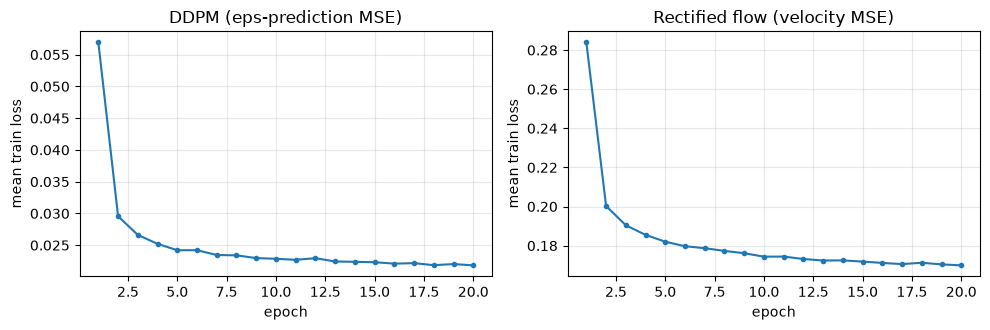

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, name, label in zip(axes, ["ddpm", "rf"], ["DDPM (eps-prediction MSE)", "Rectified flow (velocity MSE)"]):
    log = json.loads((ROOT / "runs" / f"train_{name}.json").read_text())
    ax.plot([r["epoch"] for r in log], [r["loss"] for r in log], marker="o", ms=3)
    ax.set_title(label); ax.set_xlabel("epoch"); ax.set_ylabel("mean train loss"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3. Results: quality vs. number of function evaluations

In [3]:
df = pd.DataFrame(rows)[["model", "sampler", "nfe", "fid", "coverage_entropy", "mean_confidence"]]
df = df.sort_values(["nfe", "model", "sampler"]).reset_index(drop=True)
print(f"Floor (MNIST train vs test, N={floor['n']}): fid = {floor['fid']:.2f}")
df.style.format({"fid": "{:.2f}", "coverage_entropy": "{:.3f}", "mean_confidence": "{:.3f}"}).hide(axis="index")

Floor (MNIST train vs test, N=10000): fid = 2.91


model,sampler,nfe,fid,coverage_entropy,mean_confidence
ddpm,ancestral_strided,1,1083.29,1.297,0.659
ddpm,ddim,1,1083.29,1.297,0.659
rf,euler,1,2709.95,0.136,0.390
ddpm,ancestral_strided,2,1089.10,1.300,0.655
ddpm,ddim,2,1087.88,1.304,0.655
rf,euler,2,599.21,2.032,0.769
ddpm,ancestral_strided,5,168.00,2.262,0.884
ddpm,ddim,5,102.43,2.277,0.893
rf,euler,5,65.45,2.276,0.906
ddpm,ancestral_strided,10,32.57,2.284,0.936


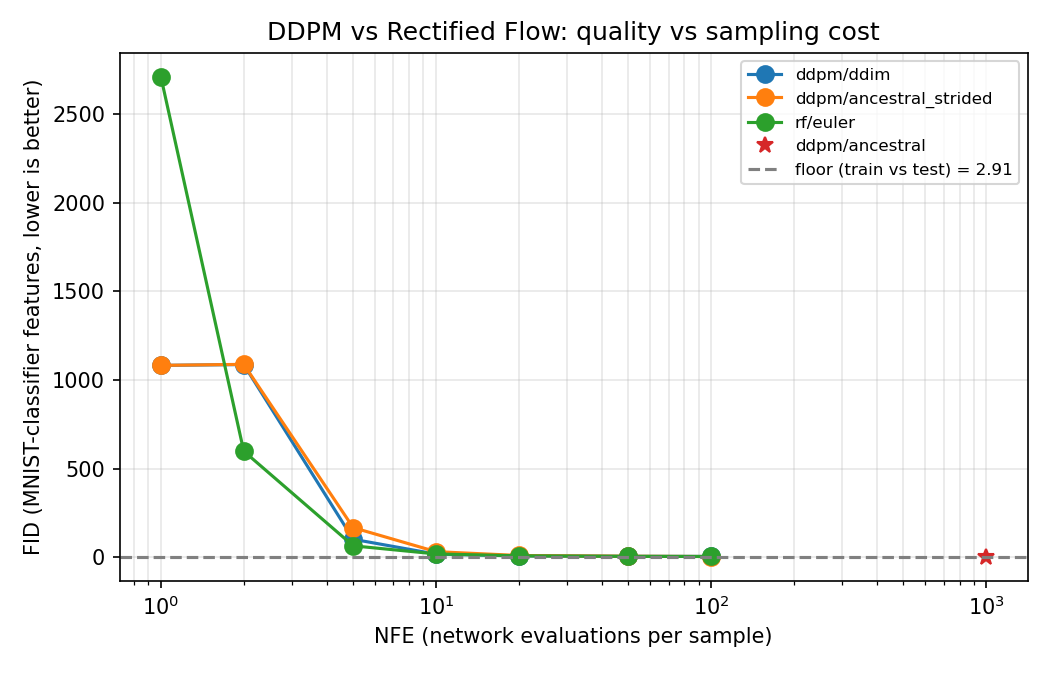

In [4]:
display(Image(filename=str(FIGS / "fid_vs_nfe.png")))

**Reading the plot.** (`fid` here is a Frechet distance in a 128-d MNIST-classifier feature space, *not* Inception FID; lower is better.)
At **1 step** DDPM-DDIM is far ahead (1083 vs 2710) because rectified flow's one Euler step
just outputs the blurry mean image. At **2 and 5 steps** rectified flow wins (599 vs 1088, 65 vs 102): its straight
paths survive coarse discretisation. From **10 steps on** the two are tied, both reaching about 6.0 at 50 steps and
5.1-5.6 at 100. The real-data floor is **2.91** (train vs test), and 1000-step DDPM ancestral sampling reaches 4.14, so neither
model closes the gap at 100 steps.

## 4. Sample grids, same noise, every NFE

Left: DDPM with DDIM. Right: rectified flow with Euler. Every grid starts from the same 64 noises.

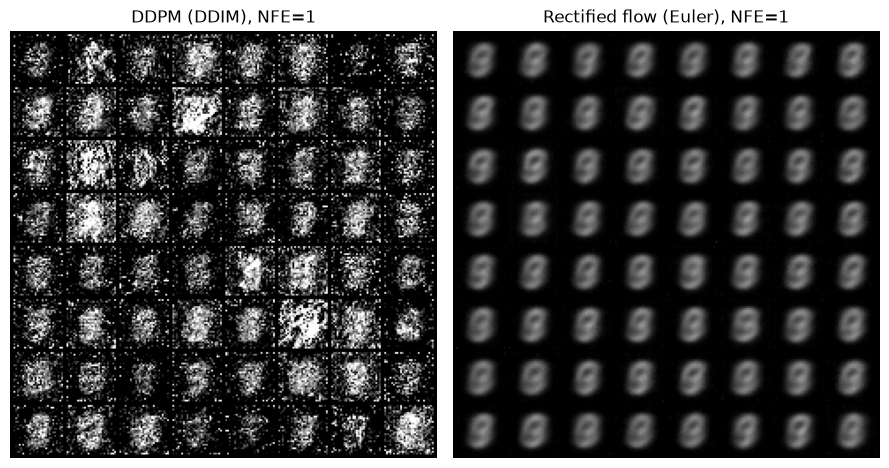

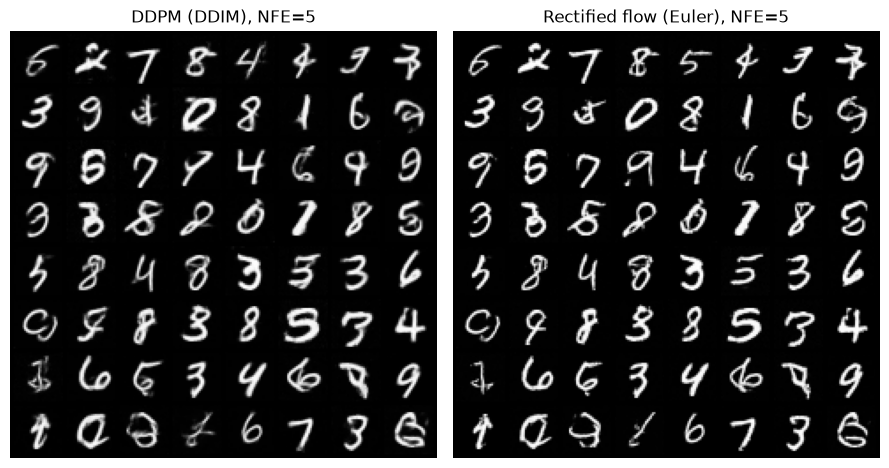

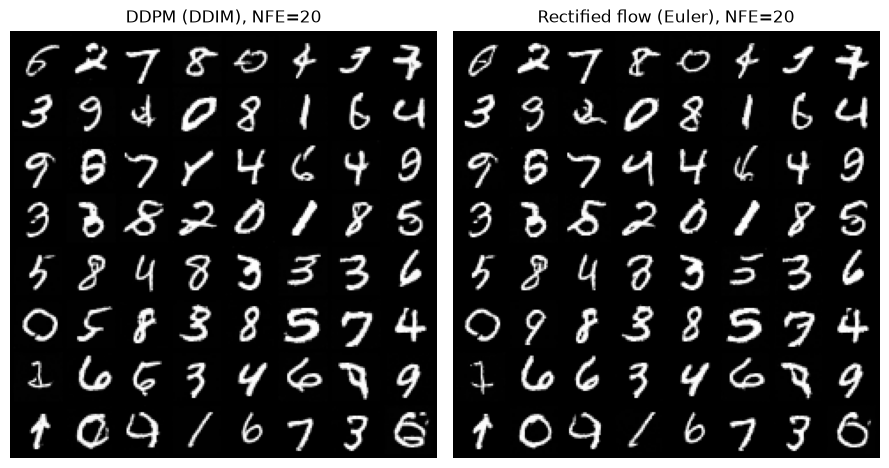

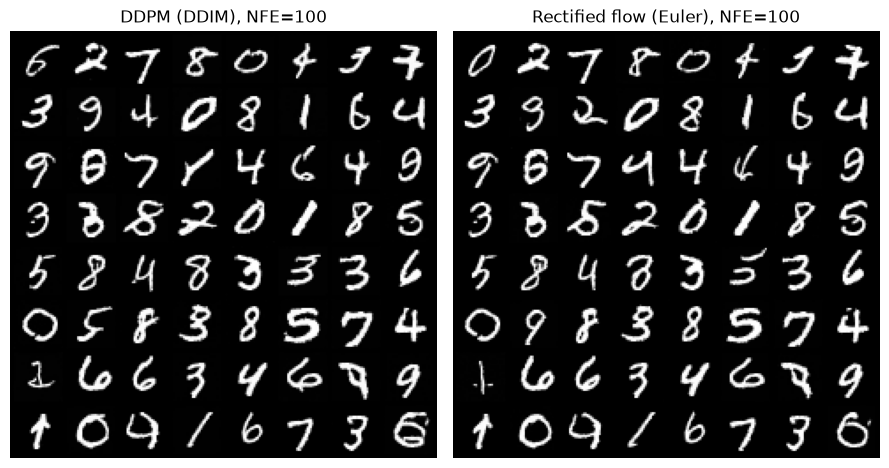

In [5]:
def show_pair(n: int) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
    for ax, f, title in zip(axes, [f"grid_ddpm_ddim_nfe{n}.png", f"grid_rf_euler_nfe{n}.png"],
                            [f"DDPM (DDIM), NFE={n}", f"Rectified flow (Euler), NFE={n}"]):
        ax.imshow(PILImage.open(FIGS / f)); ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

for n in [1, 5, 20, 100]:
    show_pair(n)

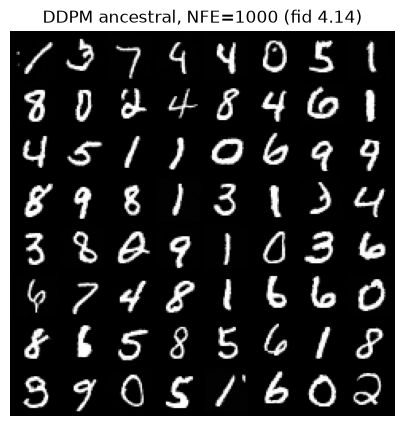

In [6]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(PILImage.open(FIGS / "grid_ddpm_ancestral_nfe1000.png"))
ax.set_title("DDPM ancestral, NFE=1000 (fid 4.14)"); ax.axis("off"); plt.show()

## 5. Learning to draw: samples after each epoch

The same 64 noises are sampled after every epoch with EMA weights (DDIM-50 for DDPM, Euler-50 for rectified flow). GIF below: DDPM on the left, rectified flow on the right.

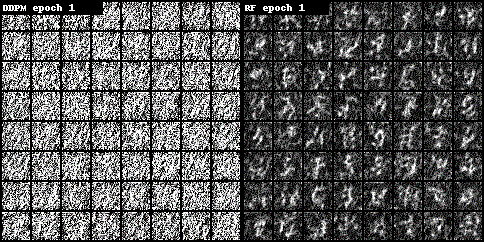

In [7]:
display(Image(filename=str(EPOCH_VIZ / "side_by_side.gif")))

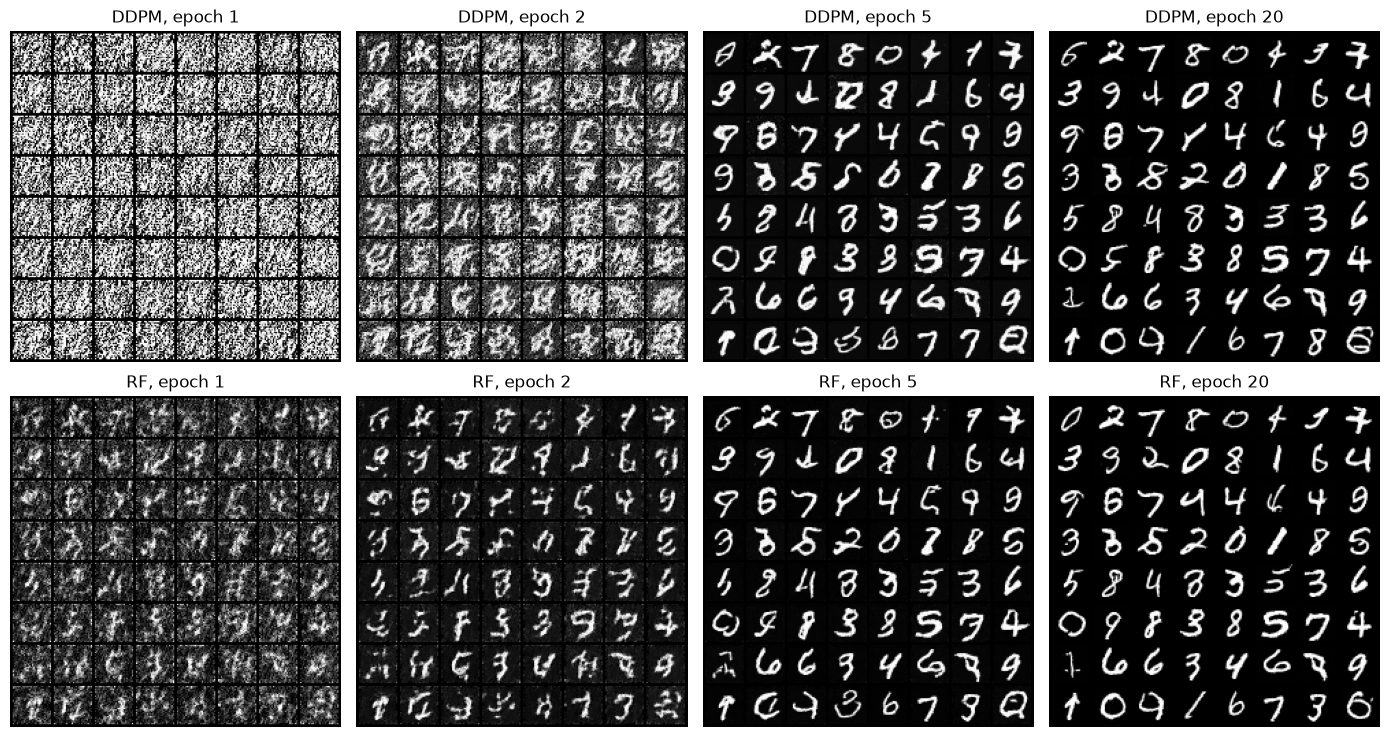

In [8]:
epochs = [1, 2, 5, 20]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.6))
for r, (name, label) in enumerate([("ddpm", "DDPM"), ("rf", "RF")]):
    for c, e in enumerate(epochs):
        axes[r, c].imshow(PILImage.open(EPOCH_VIZ / f"{name}_epoch{e:02d}.png"))
        axes[r, c].set_title(f"{label}, epoch {e}"); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

## 6. A sample's journey from noise to digit

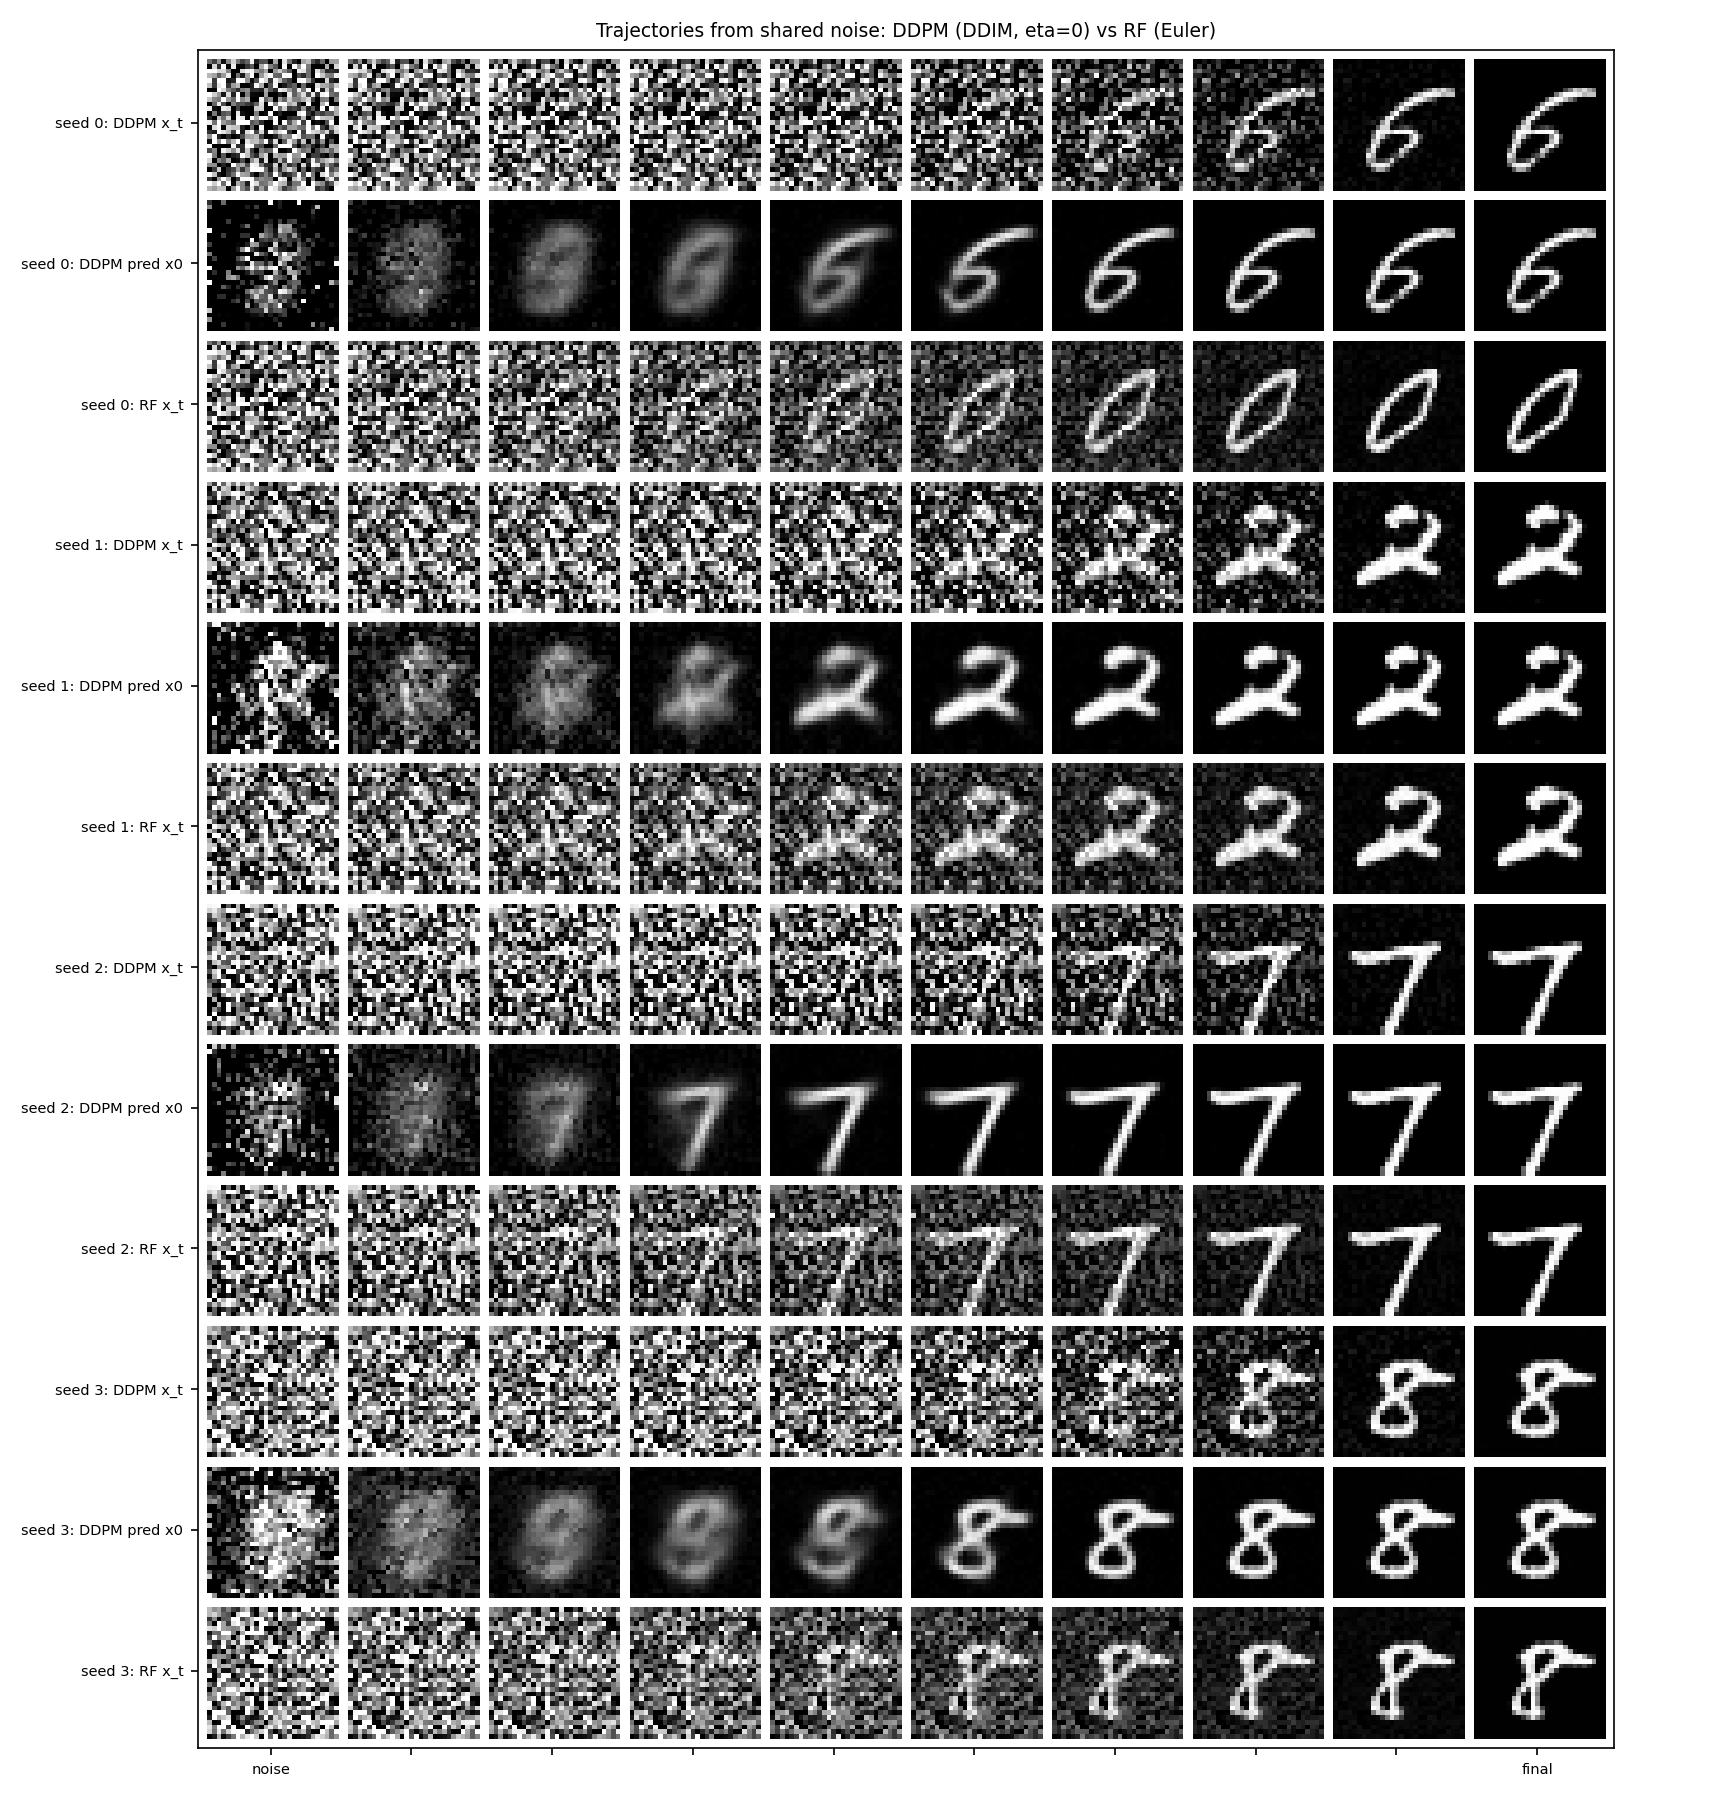

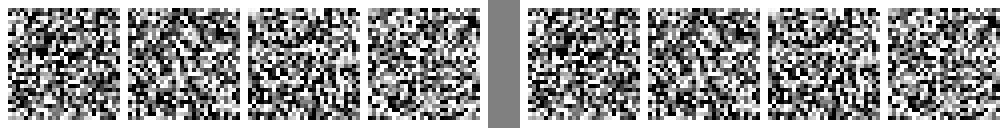

In [9]:
display(Image(filename=str(FIGS / "trajectory_strip.png")))
display(Image(filename=str(FIGS / "trajectory.gif")))

## 7. Live mini-demo

Load both EMA checkpoints, draw 16 shared noises, and sample each model with 20 network evaluations.

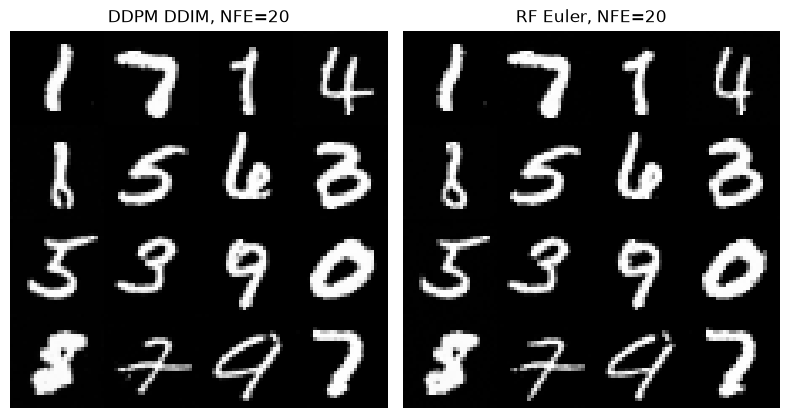

live demo took 2.7s on mps


In [10]:
import time

t0 = time.perf_counter()
models = {}
for name in ["ddpm", "rf"]:
    ck = load_checkpoint(ROOT / "checkpoints" / name / "final.pt", device)
    models[name] = build_model_from_checkpoint(ck, device)

noise = torch.randn(16, 1, 28, 28, generator=torch.Generator().manual_seed(7)).to(device)
sched = make_schedule(models["ddpm"][1]).to(device)
with torch.no_grad():
    x_ddpm, nfe_a, _ = generate(models["ddpm"][0], "ddpm", sampler="ddim", steps=20, noise=noise, sched=sched)
    x_rf, nfe_b, _ = generate(models["rf"][0], "rf", sampler="euler", steps=20, noise=noise)


def grid(x: torch.Tensor) -> np.ndarray:
    x = ((x.clamp(-1, 1) + 1) / 2).cpu().numpy()[:, 0]
    return np.concatenate([np.concatenate(list(x[i * 4:(i + 1) * 4]), axis=1) for i in range(4)], axis=0)


fig, axes = plt.subplots(1, 2, figsize=(8, 4.2))
for ax, x, title in zip(axes, [x_ddpm, x_rf], [f"DDPM DDIM, NFE={nfe_a}", f"RF Euler, NFE={nfe_b}"]):
    ax.imshow(grid(x), cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
print(f"live demo took {time.perf_counter() - t0:.1f}s on {device}")

## 8. Takeaways

1. With an identical UNet, data, optimizer, EMA and epochs, the objective and sampler are the only variables, so the comparison is clean.
2. At **1 step** DDPM-DDIM wins (1083 vs 2710); a single Euler step from rectified flow is just a blurry mean.
3. At **2 and 5 steps** rectified flow wins (599 vs 1088 and 65 vs 102): straight paths tolerate coarse steps.
4. From **10 steps up** the two are statistically tied, around 6.0 at 50 steps and 5.1-5.6 at 100, versus a 2.91 real-data floor; DDPM ancestral at 1000 steps reaches 4.14.
5. Rectified flow here is a plain 1-rectified flow (no reflow), so 1-2 step quality is limited; the metric is a classifier-feature Frechet distance, not Inception FID.

To reproduce everything (training, evaluation, cloud runs) see the project `README.md`.